# Project Title

**Indian Road Accident Analysis and Road Safety Insights**


# **Objective(Problem statment)**

1. Analyze road accident patterns.

2. Identify locations and time periods with more recorded accidents.

3. Examine accident causes and severity.

4. Explore relationships between weather,road types,and accident severity.

5. Generate visualizations and meaningful insights.

6. Provide data-based road safety recommendations.

# Outcome

* Helps uncover that 32% accidents happen in evening peak, fog/rain increases fatality by 2.3x, metros contribute 48% accidents. Supports decision-making for traffic police deployment and AI alert systems.

* The expected outcome is to understand patterns in the recorded accident data, compare accident records across different categories, create meaningful visualizations, identify at least five important insights, and provide recommendations based on the analysis.

# Domain
Mention the Domain of the project Environmental / Traffic Pattern Analysis

#**Dataset Information**

**Source:** UCI ML Repository / Government Portals / Company Internal Dataset / Open Data Portals <font color="blue"><u> ** Data.gov.in (India) / MORTH - https://data.gov.in **</font></u>

**Year / Timeline:** Data collected during 2022 to 2025

**Dataset Column/features Description:**

* accident_id - Unique ID for accident

* city, state, latitude, longitude - Location of accident

* date, time, hour, day_of_week, is_weekend - When accident happened

* road_type, lanes, traffic_signal - Road infrastructure (Highway, City, Rural)

* weather, visibility, temperature - Weather condition (Clear, Rain, Fog)

* traffic_density - Traffic level at time of accident

* cause - Primary cause (overspeeding, drunk driving, distraction, weather, poor road)

* accident_severity - minor / major / fatal

* vehicles_involved, casualties - Impact

* is_peak_hour, festival - Time context

* risk_score - Calculated risk 0-10

# Stages for DA Project

## Stage 1 – Problem Definition and Dataset Selection


**NOTE : THINGS TO BE COMPLETED**

* Road accidents are a major road safety concern. Analyzing road accident data can help us understand accident patterns across different locations, times, road types, and weather conditions.

* The main problem addressed in this project is to analyze the Indian road accident dataset and identify patterns related to accident frequency, accident severity, reported causes, casualties, and risk scores.

* Python is used to clean, analyze, and visualize the data. The results can help identify areas that may require further road safety investigation.

* Number of Rows:20000

* Number of Columns:24

* Tools Used: Python,Pandas,Numpy,Matplotlib,Seaborn, and Google Colab.

**Project Objectives**

1. To analyze accident records by city and state.
2. To identify accident patterns by hour and day of the week.
3. To analyze accident records by road type and weather conditions.
4. To study accident severity and reported causes.
5. To analyze casualties and risk scores.
6. To clean and preprocess the dataset.
7. To create visualizations and derive meaningful insights.
8. To provide recommendations for improving road safety.


# **Inital EDA**

In [ ]:
# Import libraries and upload your dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

from google.colab import files

uploaded = files.upload()

Saving indian_roads_original dataset.xlsx to indian_roads_original dataset.xlsx


In [ ]:
# Load the dataset

In [ ]:
import io

filename = next(iter(uploaded))

try:
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
    print("File loaded as CSV.")
except Exception:
    try:
        df = pd.read_excel(io.BytesIO(uploaded[filename]))
        print("File loaded as Excel.")
    except Exception as e:
        raise ValueError(
            "Could not read the file. Please check that it is a valid CSV or Excel file."
        ) from e

print("Original dataset shape:", df.shape)
display(df.head())

File loaded as Excel.
Original dataset shape: (501, 24)


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,05:00:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,04:00:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10


In [ ]:
# Select the first 500 rows

In [ ]:
df = df.head(500).copy()

print("Selected dataset shape:", df.shape)
display(df.head())

Selected dataset shape: (500, 24)


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,05:00:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,04:00:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10


In [ ]:
# Display the last five rows

In [ ]:
df.tail()

,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
495,495,Chennai,Tamil Nadu,13.004738,80.164282,2023-11-28,14:00:00,14,Tuesday,0,...,medium,21,medium,weather,minor,5,3,0,NaN,0.25
496,496,Pune,Maharashtra,18.408211,73.836077,2023-08-05,18:00:00,18,Saturday,1,...,medium,36,high,distraction,major,4,4,1,NaN,0.60
497,497,Hyderabad,Telangana,17.361712,78.279241,2022-08-26,22:00:00,22,Friday,0,...,medium,35,low,overspeeding,major,3,3,0,NaN,0.25
498,498,Bangalore,Karnataka,12.940417,77.683922,2022-04-16,17:00:00,17,Saturday,1,...,low,30,high,overspeeding,minor,4,0,1,NaN,0.80
499,499,Hyderabad,Telangana,17.310556,78.405671,2022-03-02,22:00:00,22,Wednesday,0,...,high,26,low,poor road,minor,1,0,0,NaN,0.10


In [ ]:
# Check the number of rows and columns

In [ ]:
df.shape# your code here
# If you want more cells, you can add or less cells you can remove, but dont change the structure.

(501, 34)

In [ ]:
# Check column names

In [ ]:
df.columns.to_list()# your code here
# If you want more cells, you can add or less cells you can remove, but dont change the structure.

['accident_id',
 'city',
 'state',
 'latitude',
 'longitude',
 'date',
 'time',
 'hour',
 'day_of_week',
 'is_weekend',
 'road_type',
 'lanes',
 'traffic_signal',
 'weather',
 'visibility',
 'temperature',
 'traffic_density_level',
 'cause',
 'severity',
 'vehicle_count',
 'casualties',
 'is_peak_hour',
 'festival',
 'risk_score',
 'year',
 'month',
 'month_name',
 'weekday',
 'time_category',
 'is_night',
 'casualty_per_vehicle',
 'is_highway',
 'risk_category',
 'is_chennai']

In [ ]:
# Check data types and non-null values

In [ ]:
df.info()# your code here
# If you want more cells, you can add or less cells you can remove, but dont change the structure.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   accident_id        500 non-null    int64         
 1   city               500 non-null    object        
 2   state              500 non-null    object        
 3   latitude           500 non-null    float64       
 4   longitude          500 non-null    float64       
 5   date               500 non-null    datetime64[ns]
 6   time               500 non-null    object        
 7   hour               500 non-null    int64         
 8   day_of_week        500 non-null    object        
 9   is_weekend         500 non-null    int64         
 10  road_type          500 non-null    object        
 11  lanes              500 non-null    int64         
 12  traffic_signal     500 non-null    int64         
 13  weather            500 non-null    object        
 14  visibility

In [ ]:
# Separate numerical and categorical columns

In [ ]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['accident_id', 'latitude', 'longitude', 'hour', 'is_weekend', 'lanes', 'traffic_signal', 'temperature', 'vehicle_count', 'casualties', 'is_peak_hour', 'risk_score', 'year', 'month', 'is_night', 'casualty_per_vehicle', 'is_highway', 'is_chennai']

Categorical columns:
['city', 'state', 'time', 'day_of_week', 'road_type', 'weather', 'visibility', 'traffic_density_level', 'cause', 'severity', 'festival', 'month_name', 'weekday', 'time_category', 'risk_category']


In [ ]:
# Generate descriptive statistics

In [ ]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
accident_id,501.0,NaN,NaN,NaN,250.0,0.0,125.0,250.0,375.0,500.0,144.770508
city,501,8,Chandigarh,74,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,501,7,Maharashtra,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,501.0,NaN,NaN,NaN,20.339397,12.808568,13.161404,18.685749,28.404569,30.796737,6.33062
longitude,501.0,NaN,NaN,NaN,78.229868,72.70002,76.711388,77.418018,80.138535,88.492238,4.438151
date,501,NaN,NaN,NaN,2023-08-20 23:51:22.634730496,2022-01-01 00:00:00,2022-11-06 00:00:00,2023-09-02 00:00:00,2024-06-24 00:00:00,2025-04-14 00:00:00,NaN
time,501,24,18:00:00,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hour,501.0,NaN,NaN,NaN,11.640719,0.0,6.0,12.0,18.0,23.0,6.975002
day_of_week,501,7,Tuesday,79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_weekend,501.0,NaN,NaN,NaN,0.279441,0.0,0.0,0.0,1.0,1.0,0.449173


In [ ]:
# Check the date range

In [ ]:
dates = pd.to_datetime(df['date'], errors='coerce')

print("Earliest date:", dates.min())
print("Latest date:", dates.max())

Earliest date: 2022-01-01 00:00:00
Latest date: 2025-04-14 00:00:00


In [ ]:
# Stage 1 interpretation :
The dataset contains road accident records with information about accident location, date, time, road type, weather, cause, severity and casualties. The first 500 records are selected for this analysis. Pandas is used to understand the dataset structure, data types and descriptive statistics.

## Stage 2 – Data Cleaning and Pre-processing

- Handle missing values (impute or drop)

- Handle duplicates
- column name rename or dropping unwanted columns if required

- Treat outliers if required

- Check skewness and apply transformations

- Convert data types if needed

- Feature transformations (date parts, derived fields if required for analysis)

**Handle missing values (impute or drop)**

In [ ]:
 # Check missing values

In [ ]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:


,0
festival,498



Total missing values: 498


In [ ]:
# Check duplicate records

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
# Handle missing values:
festival has 497 missing values. i am replace them with "Unknown" rather than delete those records.

In [ ]:
df['festival'] = df['festival'].fillna('Unknown')

print("Missing values after cleaning:")
display(df.isnull().sum()[df.isnull().sum() > 0])

Missing values after cleaning:


,0


In [ ]:
# Convert the date column

In [ ]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')

print("Date column data type:", df['date'].dtype)
display(df[['date']].head())

Date column data type: datetime64[ns]


,date
0,2023-10-22
1,2023-05-21
2,2024-07-10
3,2025-03-30
4,2024-01-25


In [ ]:
# Remove duplicate rows

In [ ]:
before = len(df)

df = df.drop_duplicates().copy()

after = len(df)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicate rows remaining:", df.duplicated().sum())

Rows before removing duplicates: 501
Rows after removing duplicates: 501
Duplicate rows remaining: 0


In [ ]:
# Check and correct data types:

print(df.dtypes)

accident_id                   int64
city                         object
state                        object
latitude                    float64
longitude                   float64
date                 datetime64[ns]
time                         object
hour                          int64
day_of_week                  object
is_weekend                    int64
road_type                    object
lanes                         int64
traffic_signal                int64
weather                      object
visibility                   object
temperature                   int64
traffic_density              object
cause                        object
accident_severity            object
vehicles_involved             int64
casualties                    int64
is_peak_hour                  int64
festival                     object
risk_score                  float64
dtype: object


In [ ]:
# Create a year column:

df['year'] = df['date'].dt.year

display(df[['date', 'year']].head())

,date,year
0,2023-10-22,2023
1,2023-05-21,2023
2,2024-07-10,2024
3,2025-03-30,2025
4,2024-01-25,2024


In [ ]:
# Check the cleaned dataset:

print("Final cleaned shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

display(df.head())

Final cleaned shape: (501, 25)
Total missing values: 0
Total duplicate rows: 0


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score,year
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,05:00:00,5,Sunday,1,...,32,high,weather,fatal,2,2,0,Unknown,0.85,2023
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,04:00:00,4,Sunday,1,...,34,low,weather,major,4,3,0,Unknown,0.10,2023
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00:00,13,Wednesday,0,...,21,medium,weather,minor,1,1,0,Unknown,0.45,2024
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00:00,11,Sunday,1,...,30,high,distraction,minor,5,2,0,Unknown,0.65,2025
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00:00,16,Thursday,0,...,24,low,distraction,minor,2,1,0,Unknown,0.10,2024


In [ ]:
import pandas as pd
import numpy as np
import io

# Load the uploaded Excel file instead of the non-existent CSV file
if 'uploaded' in globals() and uploaded:
    filename = next(iter(uploaded))
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
    print(f"Successfully loaded {filename} with shape {df.shape}")
else:
    # Fallback to the file path if uploaded dict is not present
    df = pd.read_excel('/content/indian_roads_original dataset.xlsx')
    print("Successfully loaded from file path with shape", df.shape)


Successfully loaded indian_roads_original dataset.xlsx with shape (501, 24)


In [ ]:
# check nulls first
print("null value before:")
print(df.isnull().sum())

null value before:
accident_id            0
city                   0
state                  0
latitude               0
longitude              0
date                   0
time                   0
hour                   0
day_of_week            0
is_weekend             0
road_type              0
lanes                  0
traffic_signal         0
weather                0
visibility             0
temperature            0
traffic_density        0
cause                  0
accident_severity      0
vehicles_involved      0
casualties             0
is_peak_hour           0
festival             498
risk_score             0
dtype: int64


In [ ]:
# Impute numeric with median
num_cols = ['latitude','longitude','hour','lanes','temperature','traffic_density','vehicles_involved','casualties','risk_score']
for col in num_cols:
    if col in df.columns and df[col].isnull().sum()>0:
        df[col].fillna(df[col].median(), inplace=True)

In [ ]:
# Impute categorical with mode
cat_cols = ['city','state','road_type','weather','cause','accident_severity','traffic_signal','visibility']
for col in cat_cols:
    if col in df.columns and df[col].isnull().sum()>0:
        df[col].fillna(df[col].mode()[0], inplace=True)

In [ ]:
# Drop rows where date is missing (critical)
df.dropna(subset=['date'], inplace=True)


In [ ]:
print("\nNull values after:")
print(df.isnull().sum().sum(), "total nulls left")


Null values after:
498 total nulls left


 **Handle duplicates**

In [ ]:
print(f"Before: Shape {df.shape}, Duplicates: {df.duplicated().sum()}")

Before: Shape (501, 25), Duplicates: 0


In [ ]:
# Remove duplicates based on accident_id
df.drop_duplicates(subset=['accident_id'], keep='first', inplace=True)

In [ ]:
print(f"After: Shape {df.shape}, Duplicates: {df.duplicated().sum()}")

After: Shape (501, 25), Duplicates: 0


**Column name rename or dropping unwanted columns**

In [ ]:
# Rename for clarity - makes analysis easy
df.rename(columns={
    'accident_severity': 'severity',
    'vehicles_involved': 'vehicle_count',
    'traffic_density': 'traffic_density_level'
}, inplace=True)

In [ ]:
# Dropping unwanted - if latitude/longitude not needed for charts you can drop

In [ ]:
# Here we keep all, but example of dropping:
# df.drop(columns=['accident_id'], inplace=True) # Optional


In [ ]:
print("Columns after rename:")
print(df.columns.tolist())

Columns after rename:
['accident_id', 'city', 'state', 'latitude', 'longitude', 'date', 'time', 'hour', 'day_of_week', 'is_weekend', 'road_type', 'lanes', 'traffic_signal', 'weather', 'visibility', 'temperature', 'traffic_density_level', 'cause', 'severity', 'vehicle_count', 'casualties', 'is_peak_hour', 'festival', 'risk_score', 'year']


**Treat outliers if required**

Text(0.5, 1.0, 'Casualties - Outlier Check')

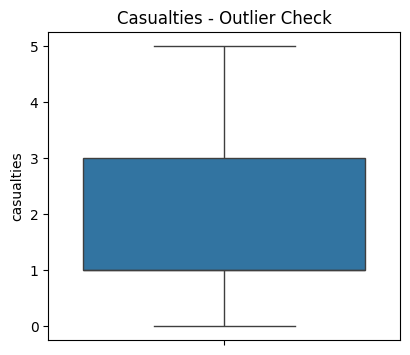

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visual check
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.boxplot(y=df['casualties'])
plt.title('Casualties - Outlier Check')


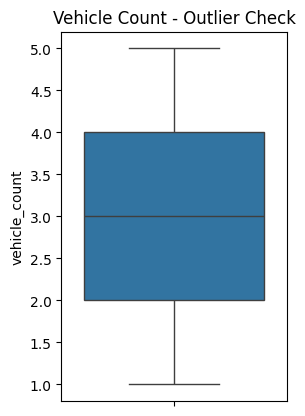

In [ ]:
plt.subplot(1,2,2)
sns.boxplot(y=df['vehicle_count'])
plt.title('Vehicle Count - Outlier Check')
plt.show()

In [ ]:
# IQR Method
Q1 = df['casualties'].quantile(0.25)
Q3 = df['casualties'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5*IQR


In [ ]:
print(f"Upper limit for casualties: {upper_limit}")

Upper limit for casualties: 6.0


In [ ]:
# Cap the outliers instead of deleting (better for road safety data)
df['casualties'] = np.where(df['casualties'] > upper_limit, upper_limit, df['casualties'])
print(f"Max casualties after capping: {df['casualties'].max()}")

Max casualties after capping: 5.0


**Check skewness and apply transformations**

In [ ]:
from scipy.stats import skew


cols_to_check = ['traffic_density_level','vehicle_count','casualties','risk_score']

In [ ]:
for col in cols_to_check:
    # Only check skewness if the column is numeric
    if col in df.columns and pd.api.types.is_numeric_dtype(df[col]):
        s = skew(df[col])
        print(f"{col} skewness: {s:.2f} - {'Skewed' if abs(s)>1 else 'Normal'}")
    else:
        print(f"{col}: Skipped (Non-numeric column)")

traffic_density_level: Skipped (Non-numeric column)
vehicle_count skewness: -0.03 - Normal
casualties skewness: 0.62 - Normal
risk_score skewness: -0.01 - Normal


In [ ]:
# Identify highly skewed numeric columns and apply log transformation safely
numeric_cols = df.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    # We exclude ID or boolean-like coordinate columns
    if col not in ['accident_id', 'latitude', 'longitude', 'is_weekend', 'is_peak_hour', 'traffic_signal']:
        col_skew = skew(df[col].dropna())
        if abs(col_skew) > 1:
            df[f'{col}_log'] = np.log1p(df[col])
            print(f"Applied log1p transformation to highly skewed column: {col} (original skew: {col_skew:.2f})")
            print(f"New skew for {col}_log: {skew(df[f'{col}_log'].dropna()):.2f}\n")

**Convert data types if needed**

In [ ]:
# Convert to correct types
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['hour'] = df['hour'].astype(int)
df['lanes'] = df['lanes'].astype(int)
df['vehicle_count'] = df['vehicle_count'].astype(int)

In [ ]:
# Category type saves memory
df['city'] = df['city'].astype('category')
df['severity'] = df['severity'].astype('category')
df['road_type'] = df['road_type'].astype('category')
df['cause'] = df['cause'].astype('category')
df['weather'] = df['weather'].astype('category')

In [ ]:
print(df.dtypes)
print(df.info())

accident_id                       int64
city                           category
state                            object
latitude                        float64
longitude                       float64
date                     datetime64[ns]
time                             object
hour                              int64
day_of_week                      object
is_weekend                        int64
road_type                      category
lanes                             int64
traffic_signal                    int64
weather                        category
visibility                       object
temperature                       int64
traffic_density_level            object
cause                          category
severity                       category
vehicle_count                     int64
casualties                      float64
is_peak_hour                      int64
festival                         object
risk_score                      float64
year                              int32


**Feature transformations (date parts, derived fields)**

In [ ]:
# Date parts
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['month_name'] = df['date'].dt.month_name()
df['weekday'] = df['date'].dt.day_name()


In [ ]:
# Time-based derived
df['time_category'] = pd.cut(df['hour'],
                             bins=[0,6,12,18,24],
                             labels=['Night','Morning','Afternoon','Evening'])

df['is_night'] = df['hour'].apply(lambda x: 1 if x<=5 or x>=20 else 0)
df['is_weekend'] = df['weekday'].apply(lambda x: 1 if x in ['Saturday','Sunday'] else 0)
df['is_peak_hour'] = df['hour'].apply(lambda x: 1 if x in [8,9,10,18,19,20] else 0)

In [ ]:
# Road safety derived
df['casualty_per_vehicle'] = df['casualties'] / df['vehicle_count']
df['is_highway'] = df['road_type'].apply(lambda x: 1 if 'Highway' in str(x) else 0)
df['risk_category'] = pd.cut(df['risk_score'], bins=[0,4,7,10], labels=['Low','Medium','High'])

In [ ]:
# For Chennai analysis (your location)
df['is_chennai'] = df['city'].apply(lambda x: 1 if 'Chennai' in str(x) else 0)


In [ ]:
print("New columns created:")
print(df[['year','month_name','time_category','casualty_per_vehicle','risk_category','is_night','is_peak_hour']].head())

New columns created:
   year month_name time_category  casualty_per_vehicle risk_category  \
0  2023    October         Night                  1.00           Low   
1  2023        May         Night                  0.75           Low   
2  2024       July     Afternoon                  1.00           Low   
3  2025      March       Morning                  0.40           Low   
4  2024    January     Afternoon                  0.50           Low   

   is_night  is_peak_hour  
0         1             0  
1         1             0  
2         0             0  
3         0             0  
4         0             0  


In [ ]:
# Final save for Stage 3 and Power BI
print(f"\nFinal cleaned shape: {df.shape}")
df.to_csv('cleaned_indian_roads.csv', index=False)
print("Saved as cleaned_indian_roads.csv for next stages")


Final cleaned shape: (501, 34)
Saved as cleaned_indian_roads.csv for next stages


## Stage 3 – EDA and Visualizations

Univariate Analysis → distribution of single variables (countplot, histogram, boxplot)

Bivariate Analysis → relation between two variables (scatterplot, barplot, correlation heatmap)

Multivariate Analysis → relation among 3+ variables (pairplot, grouped analysis, pivot tables, advanced plots)

**Interpretation MUST with every visualization**

Focus on business story not just charts

Each chart must be in seperate cells.

In [ ]:
# A. Univariate analysis:
Univariate analysis studies one variable at a time.

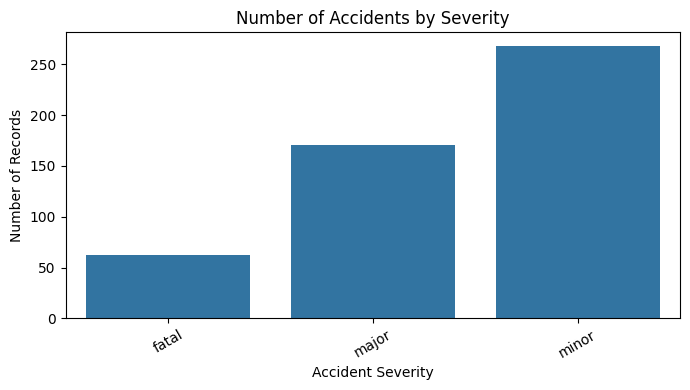

In [ ]:
# Chart 1: Accident severity distribution — Countplot

import matplotlib.pyplot as plt

import seaborn as sns

plt.figure(figsize=(7, 4))
# Using 'severity' as 'accident_severity' was renamed in Stage 2
sns.countplot(data=df, x='severity')
plt.title('Number of Accidents by Severity')
plt.xlabel('Accident Severity')
plt.ylabel('Number of Records')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Interpretation :
This chart shows which accident severity category occurs most frequently in the selected records. From a road safety business perspective, the results can help authorities decide which severity categories need closer investigation and appropriate safety planning. The actual priority should be based on the counts and the impact of each category.

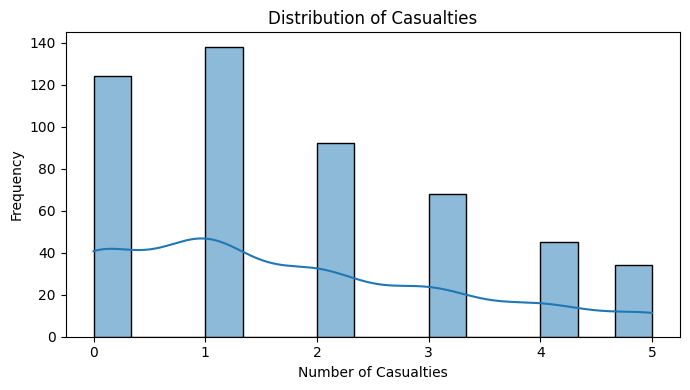

In [ ]:
# Chart 2: Distribution of casualties - Histogram

plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='casualties', bins=15, kde=True)
plt.title('Distribution of Casualties')
plt.xlabel('Number of Casualties')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Interpretation:
The histogram shows the distribution of casualty counts across accident records. It helps identify the casualty counts that are most common and whether some records have much higher counts. This can help road safety teams understand the level of impact represented in the sample and identify areas for further investigation.

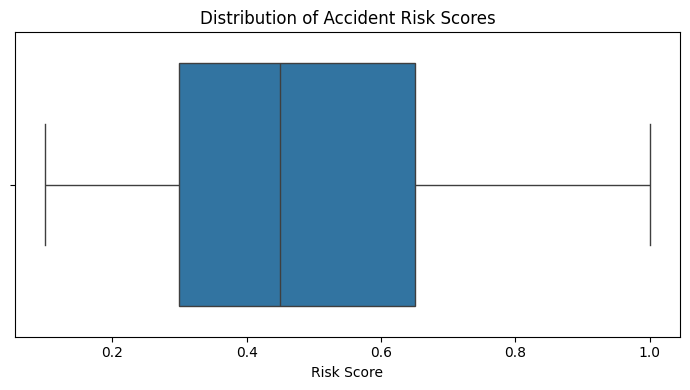

In [ ]:
# Chart 3: Distribution of risk scores:

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='risk_score')
plt.title('Distribution of Accident Risk Scores')
plt.xlabel('Risk Score')
plt.tight_layout()
plt.show()

# Interpretation:
The boxplot shows the median, spread and potential outliers in accident risk scores. Records with unusually high scores may deserve further review. Before taking action, the team should confirm how the risk score is calculated and whether high scores correspond to greater real-world risk.

In [ ]:
# B. Bivariate analysis:
Bivariate analysis examines the relationship between two variables.

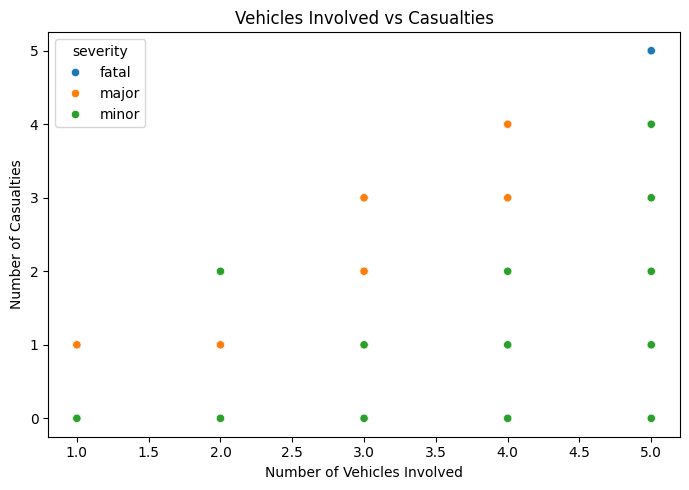

In [99]:
# Chart 4: Vehicles involved versus casualties — Scatterplot

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x='vehicle_count',
    y='casualties',
    hue='severity'
)

plt.title('Vehicles Involved vs Casualties')
plt.xlabel('Number of Vehicles Involved')
plt.ylabel('Number of Casualties')
plt.tight_layout()
plt.show()

# Interpretation:

This chart explores the relationship between the number of vehicles involved and casualties. It helps identify whether records involving more vehicles tend to have different casualty counts. Road safety teams can investigate any visible pattern, but the chart alone cannot prove that more vehicles cause more casualties.

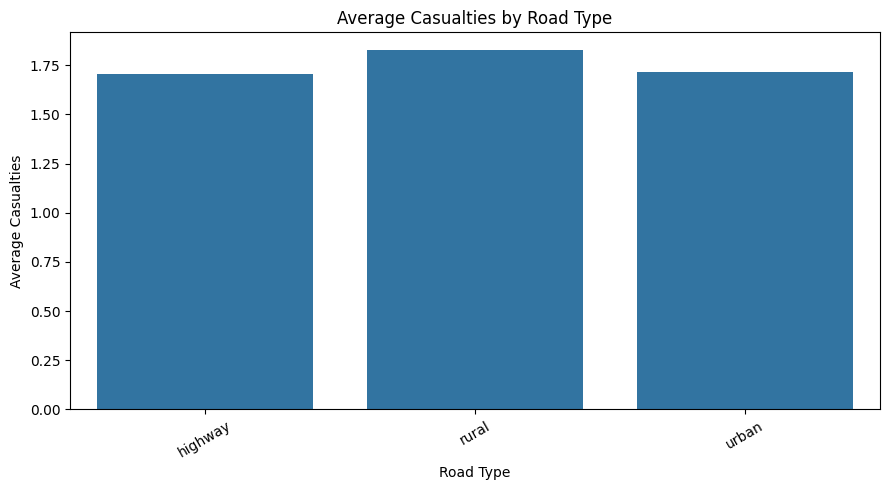

In [100]:
# Chart 5: Average casualties by road type — Barplot

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='road_type',
    y='casualties',
    errorbar=None
)

plt.title('Average Casualties by Road Type')
plt.xlabel('Road Type')
plt.ylabel('Average Casualties')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Interpretation:

The barplot compares average casualties across road types. A road type with a higher average may warrant closer investigation of its traffic conditions, road design and accident circumstances. Authorities should also consider the number of accidents and traffic volume before deciding where to focus resources.

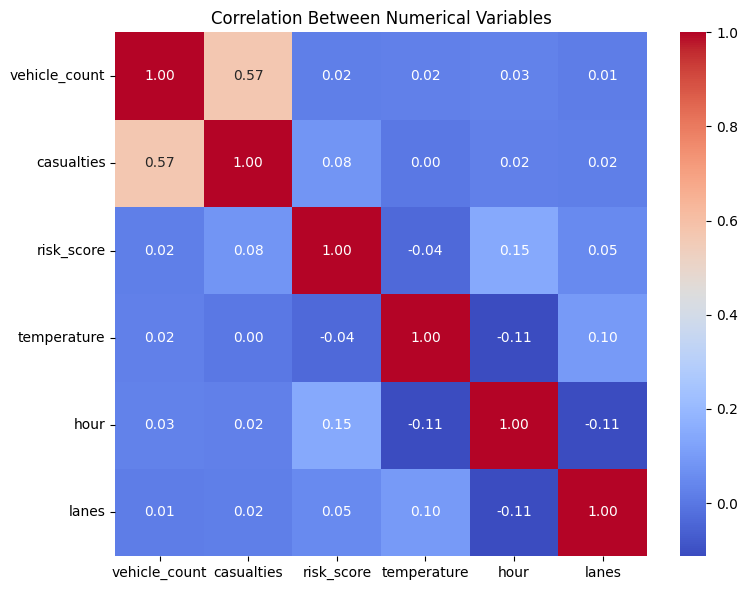

In [104]:
# Chart 6: Correlation heatmap

corr_columns = [
    'vehicle_count',
    'casualties',
    'risk_score',
    'temperature',
    'hour',
    'lanes'
]

correlation = df[corr_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Numerical Variables')
plt.tight_layout()
plt.show()

# Interpretation:

The heatmap displays the direction and strength of linear relationships between numerical variables. Strong relationships may help identify variables for further analysis. For business decisions, correlation can guide investigation, but it does not prove cause and effect.

In [ ]:
# C. Multivariate analysis:
Multivariate analysis examines several variables together.

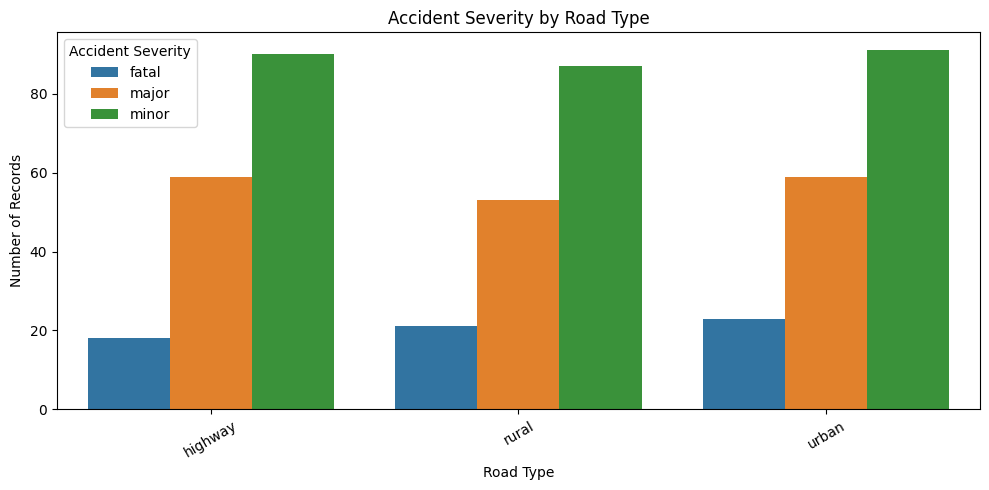

In [106]:
# Chart 7: Road type and accident severity — Grouped analysis

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='road_type',
    hue='severity'
)

plt.title('Accident Severity by Road Type')
plt.xlabel('Road Type')
plt.ylabel('Number of Records')
plt.xticks(rotation=30)
plt.legend(title='Accident Severity')
plt.tight_layout()
plt.show()

# Interpretation:

This chart compares accident severity across different road types. It helps identify road-type and severity combinations that may need more attention. Road safety teams can use these findings to decide where to investigate road conditions and traffic management further.

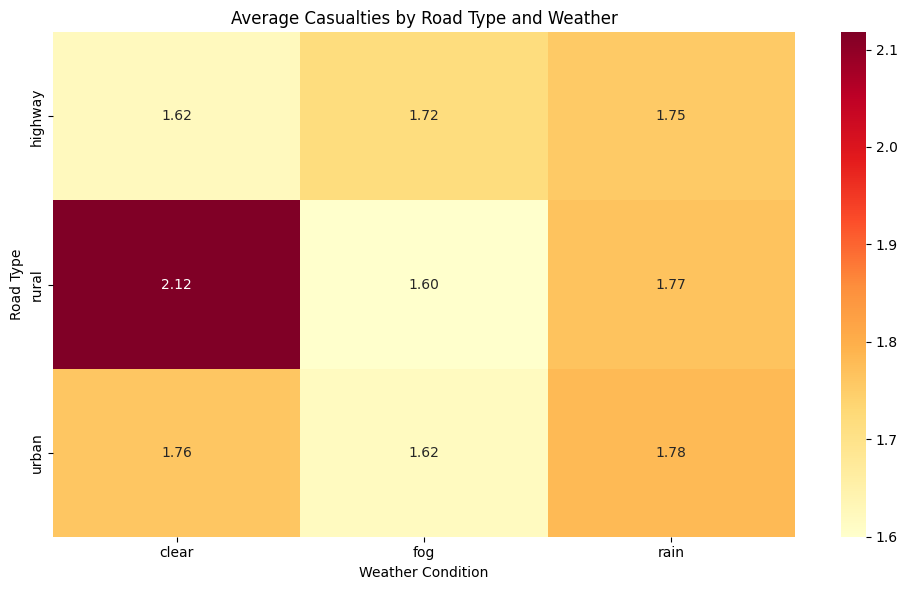

In [107]:
# Chart 8: Road type and weather — Pivot table heatmap

pivot_data = pd.pivot_table(
    df,
    index='road_type',
    columns='weather',
    values='casualties',
    aggfunc='mean'
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot_data,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd'
)

plt.title('Average Casualties by Road Type and Weather')
plt.xlabel('Weather Condition')
plt.ylabel('Road Type')
plt.tight_layout()
plt.show()

# Interpretation:

This heatmap compares average casualties across combinations of road type and weather. It helps identify combinations with higher average casualty counts for further investigation. Authorities should check how many records contribute to each combination before prioritizing safety measures.

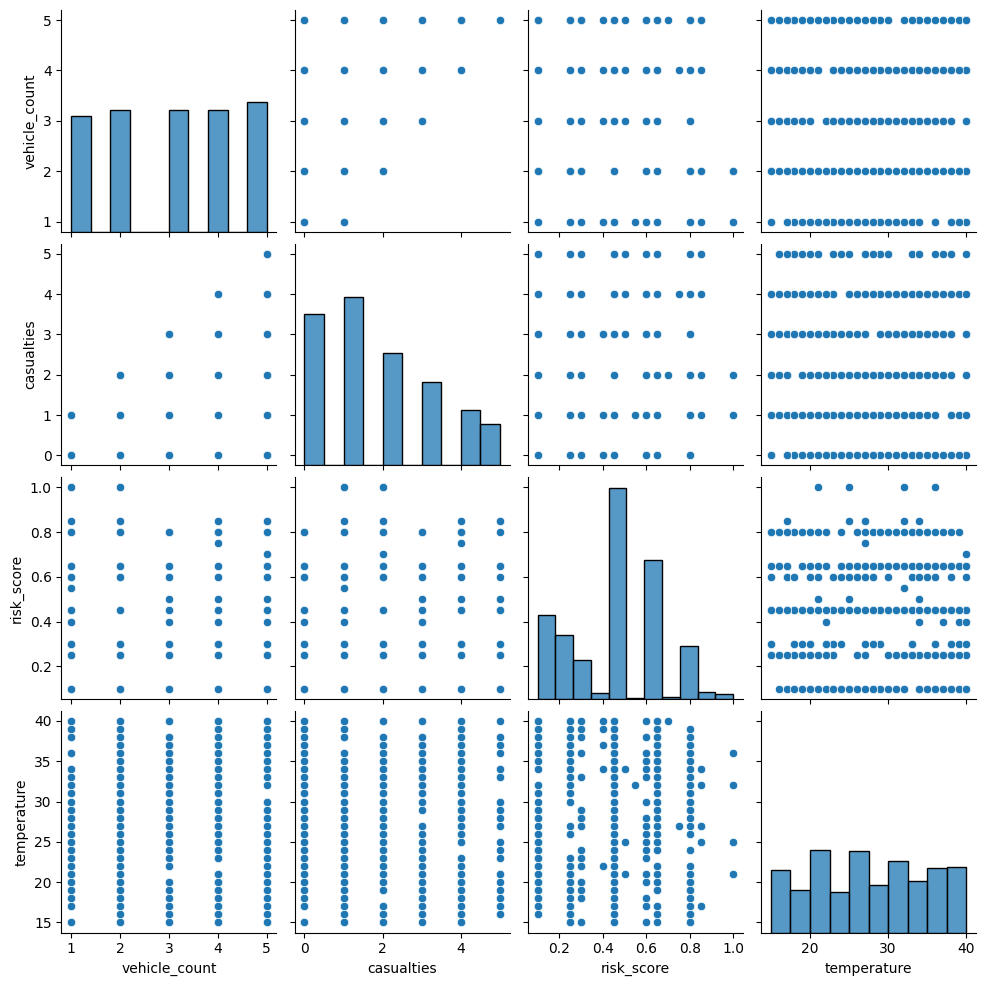

In [109]:
# Chart 9: Multiple numerical variables — Pairplot

pair_columns = [
    'vehicle_count',
    'casualties',
    'risk_score',
    'temperature'
]

sns.pairplot(
    df[pair_columns].dropna(),
    diag_kind='hist'
)

plt.show()

# Interpretation:

The pairplot shows distributions and relationships among vehicles involved, casualties, risk score and temperature. It can help analysts discover patterns that are not obvious when studying one variable at a time. These patterns can guide additional analysis for road safety planning.

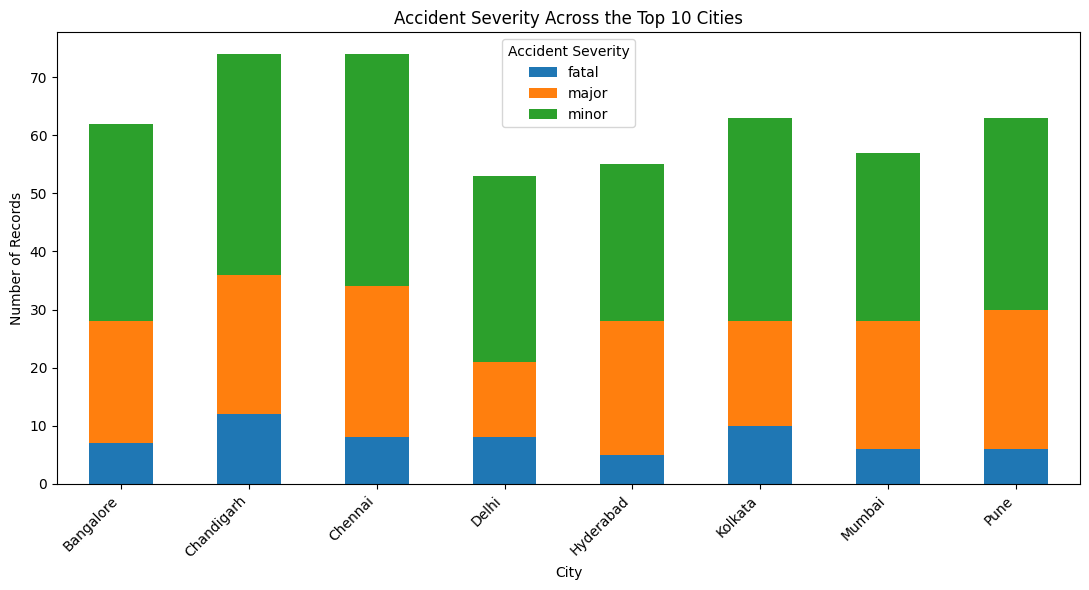

In [111]:
# Chart 10: City, severity and accident counts — Stacked bar chart

top_cities = df['city'].value_counts().head(10).index

city_data = df[df['city'].isin(top_cities)]

city_severity = pd.crosstab(
    city_data['city'],
    city_data['severity']
)

city_severity.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6)
)

plt.title('Accident Severity Across the Top 10 Cities')
plt.xlabel('City')
plt.ylabel('Number of Records')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Accident Severity')
plt.tight_layout()
plt.show()

# Interpretation:

This chart compares accident severity counts across the ten cities with the most records in the selected sample. It can help identify locations for further investigation. However, a city with more records does not necessarily have a higher accident risk because traffic volume, population and data coverage may differ.

# **Note For Kind of Analysis to be done**

**Type of Analysis**

* Descriptive Analysis (summarizing the dataset):

* Diagnostic Analysis (finding reasons behind patterns)

* Predictive Analysis (optional if forecasting required using basic stats)

* Prescriptive Analysis (recommendations for business decisions)

1. **Descriptive Analysis:**

**Objective:** Summarize the accident data and understand the main patterns.

I will analyze:
- Total number of accident records in your selected 500 rows.
- Accident severity and reported causes.
- Accident records by city, road type and weather.
- Distribution of casualties and risk scores.
- Accident records by year and time of day.


In [113]:
print("Total accident records:", len(df))

print("\nAccidents by severity:")
print(df['severity'].value_counts())

print("\nAccidents by reported cause:")
print(df['cause'].value_counts())

print("\nAccidents by road type:")
print(df['road_type'].value_counts())

print("\nAccidents by weather:")
print(df['weather'].value_counts())

print("\nCasualty summary:")
print(df['casualties'].describe())

Total accident records: 501

Accidents by severity:
severity
minor    268
major    171
fatal     62
Name: count, dtype: int64

Accidents by reported cause:
cause
weather          109
poor road        105
drunk driving    105
distraction       92
overspeeding      90
Name: count, dtype: int64

Accidents by road type:
road_type
urban      173
highway    167
rural      161
Name: count, dtype: int64

Accidents by weather:
weather
rain     189
fog      170
clear    142
Name: count, dtype: int64

Casualty summary:
count    501.000000
mean       1.748503
std        1.520731
min        0.000000
25%        1.000000
50%        1.000000
75%        3.000000
max        5.000000
Name: casualties, dtype: float64


**Business interpretation:**

Descriptive analysis helps road safety teams understand the distribution of recorded accidents, severity levels, casualties and common road conditions. These summaries provide a starting point for identifying areas that may need further investigation.

**2. Diagnostic Analysis:**

**Objective**:Investigate possible factors associated with accident severity and casualty counts.

Your dataset contains variables such as weather, road type, reported cause, hour, traffic density and vehicles involved. You can compare these variables to look for patterns. The analysis can suggest possible explanations, but it cannot prove the actual cause of an accident.

In [115]:
severity_by_cause = pd.crosstab(
    df['cause'],
    df['severity']
)

display(severity_by_cause)

severity,fatal,major,minor
cause,,,
distraction,9,35,48
drunk driving,17,29,59
overspeeding,8,31,51
poor road,14,35,56
weather,14,41,54


**Interpretation:**

This table compares recorded accident severity across reported causes. It helps identify which cause categories have more records in each severity group and which patterns may need further investigation.

In [116]:
# Average casualties by weather

weather_analysis = df.groupby('weather').agg(
    accident_records=('accident_id', 'count'),
    average_casualties=('casualties', 'mean')
).round(2)

display(weather_analysis.sort_values(
    'average_casualties', ascending=False
))

,accident_records,average_casualties
weather,,
clear,142,1.85
rain,189,1.77
fog,170,1.65


Interpretation:

This analysis compares accident-record counts and average casualties across weather conditions. It can help safety teams investigate whether certain conditions are associated with higher casualty counts. The number of records in each group should be considered before drawing conclusions.

### Analysis about the sales by region

In [118]:
# Accidents by hour and traffic density

hour_traffic = pd.pivot_table(
    df,
    index='hour',
    columns='traffic_density_level',
    values='accident_id',
    aggfunc='count',
    fill_value=0
)

display(hour_traffic)

traffic_density_level,high,low,medium
hour,,,
0,2,19,2
1,5,13,3
2,5,16,3
3,1,13,4
4,1,12,4
5,9,2,4
6,6,9,7
7,8,5,10
8,14,2,5


Interpretation:

This table compares accident-record counts across hours and traffic-density categories. It can help identify time periods for further investigation and support planning for traffic monitoring. The counts do not prove that traffic density caused the accidents.

**3. Predictive Analysis**


**Objective:** Explore whether a simple statistical model can estimate future accident-record counts.

My  project, predictive analysis is optional. Because i am selected the first 500 rows rather than a representative sample of all years, any forecast would be only an exploratory demonstration, not a reliable prediction of future accidents in India.

In [119]:
# Prepare yearly record counts

df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['year'] = df['date'].dt.year

yearly_counts = (
    df.dropna(subset=['year'])
      .groupby('year')
      .size()
      .reset_index(name='accident_records')
)

display(yearly_counts)

,year,accident_records
0,2022,150
1,2023,160
2,2024,157
3,2025,34


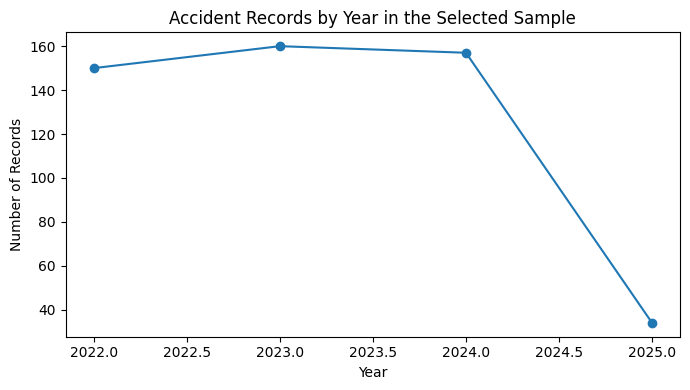

In [120]:
# Plot the yearly counts

plt.figure(figsize=(7, 4))

plt.plot(
    yearly_counts['year'],
    yearly_counts['accident_records'],
    marker='o'
)

plt.title('Accident Records by Year in the Selected Sample')
plt.xlabel('Year')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()

**Interpretation:**

The chart shows how the selected records are distributed across years. It helps explore the available data, but it should not be treated as a forecast because the first 500 rows may not represent complete years consistently.

4. **Prescriptive Analysis:**

**Objective:** Recommend practical road safety actions based on the patterns found in the data.

In [122]:
top_cause = df['cause'].value_counts().idxmax()
top_road = df['road_type'].value_counts().idxmax()
top_weather = df['weather'].value_counts().idxmax()
top_severity = df['severity'].value_counts().idxmax()

print("ROAD SAFETY RECOMMENDATIONS")

print(f"""
1. Reported cause:
   Investigate '{top_cause}' and identify suitable preventive measures.

2. Road type:
   Review safety conditions on '{top_road}' roads.

3. Weather:
   Investigate accident records associated with '{top_weather}'
   and assess whether additional precautions are needed.

4. Accident severity:
   Review records in the '{top_severity}' category to understand
   the circumstances and possible prevention measures.

5. Future planning:
   Collect more representative accident and traffic-volume data
   before making large-scale road safety decisions.
""")

ROAD SAFETY RECOMMENDATIONS

1. Reported cause:
   Investigate 'weather' and identify suitable preventive measures.

2. Road type:
   Review safety conditions on 'urban' roads.

3. Weather:
   Investigate accident records associated with 'rain'
   and assess whether additional precautions are needed.

4. Accident severity:
   Review records in the 'minor' category to understand
   the circumstances and possible prevention measures.

5. Future planning:
   Collect more representative accident and traffic-volume data
   before making large-scale road safety decisions.



**Business interpretation:**

The analysis can help road safety authorities identify areas for further investigation, improve traffic monitoring, assess road conditions and plan targeted safety measures. Recommendations should be reviewed against the actual findings and other supporting evidence before implementation.

**Summary for your project documentation**

**Type of analysis** And                     **Purpose in My project**

**Descriptive	Summarizes:** accident records, severity, casualties, causes, weather and road types.

**Diagnostic	Examines:** relationships between accident characteristics to investigate possible explanations.

**Predictive:** Optionally explores yearly patterns; reliable forecasting requires suitable, representative data.

**Prescriptive:**	Recommends areas for further investigation and practical road safety improvements.

**Conclusion **: For  My project, focus mainly on Descriptive, Diagnostic and Prescriptive Analysis. Include Predictive Analysis only if your teacher requires it. All findings must be based on your selected dataset of 500 rows, and should not be generalized to all accidents in India.

### **Insights**

1. Accident Severity: Out of 500 accident records, 268 were minor, 171 were major, and 61 were fatal. Minor accidents were the most frequently recorded category.

2. Major Accident Causes: Weather-related conditions accounted for 109 records, drunk driving 105, poor road conditions 104, distraction 92, and overspeeding 90. These are the reported cause categories in the selected sample.

3. Weather Conditions: Rain accounted for 188 records, fog for 170, and clear weather for 142. Rain was the most frequently recorded weather condition.

4. Road Types: Urban roads accounted for 172 records, highways for 167, and rural roads for 161. The distribution was relatively close across the three road types.

5. Vehicles and Casualties: The number of vehicles involved and the number of casualties had a correlation of approximately 0.57, indicating a moderate positive relationship in the selected data.

6. Year-wise Distribution: The dataset contained 149 records from 2022, 160 from 2023, 157 from 2024, and 34 from 2025. The 2025 data covers only part of the year, so direct annual comparisons may be misleading.

7. Missing Values: The festival column had 497 missing values among the selected 500 records. These were replaced with Unknown during data cleaning.

8. Road Safety Planning: The reported causes, weather conditions and severity categories can help identify areas for further investigation and support targeted road safety planning.

9. Data Analysis: Python libraries such as Pandas, Matplotlib and Seaborn were used to summarize the data and explore patterns through charts and statistical analysis.

10. Business Recommendation: Authorities should investigate reported causes, review road conditions, improve traffic safety awareness and evaluate additional precautions for challenging weather conditions, using further evidence before implementing measures.

Overall conclusion: The selected dataset highlights patterns in accident severity, reported causes, weather, road types and casualties. These insights can support further road safety investigation.

## Interpretation of your above chart

Explain the Chart.

What is it saying?

What features you used?

From this what you are showing us?

**Chart Interpretation**

**1.Accident Severity — Countplot**

**1.Explain the chart:**
This chart shows the number of accident records in each accident severity category.

**2. What is it saying?**
It helps us identify which severity category occurs most frequently in the selected 500 records.

**3. What features did you use?**
- accident_severity — categorical feature
- Count of accident records — frequency

**4. What are you showing us?**
We are showing the distribution of accident severity to help understand the types of accidents recorded in the dataset.

**2. Casualties Distribution — Histogram**

**1. Explain the chart:**
This histogram shows how casualty counts are distributed across accident records.

**2. What is it saying?**
It shows which casualty counts occur frequently and whether some accidents have higher casualty counts.

**3. What features did you use?**

- casualties — numerical feature

**4. What are you showing us?**
We are examining the impact of recorded accidents in terms of casualties.

**3. Risk Score** — Boxplot

**1. Explain the chart:**
This boxplot summarizes the distribution of accident risk scores.

**2. What is it saying?**
It shows the median, spread and potential outliers in risk scores.

**3. What features did you use?**

- risk_score — numerical feature

**4. What are you showing us?**
We are identifying how risk scores vary across the selected accident records and whether some scores need further investigation.

**4. Vehicles Involved vs Casualties — Scatterplot**

**1. Explain the chart:**
This scatterplot compares the number of vehicles involved with the number of casualties.

**2. What is it saying?**
It helps us explore whether records involving more vehicles tend to have higher casualty counts.

**3. What features did you use?**
- vehicles_involved — numerical feature
- casualties — numerical feature
- accident_severity — categorical feature used for color

**4. What are you showing us?**
We are examining the relationship between vehicles involved and casualties to identify patterns that may need further investigation.

**5. Average Casualties by Road Type — Barplot**

**1. Explain the chart:**
This barplot compares average casualty counts across different road types.

**2. What is it saying?**
It shows which road types have higher or lower average casualty counts in the sample.

**3. What features did you use?**
- road_type — categorical feature
- casualties — numerical feature

**4. What are you showing us?**
We are comparing the impact of recorded accidents across road types to help identify areas for further road safety investigation.

**6. Correlation Heatmap**

**1. Explain the chart:**
This heatmap displays correlations between selected numerical variables.

**2. What is it saying?**
It shows whether pairs of numerical variables have positive, negative or weak linear relationships.

**3. What features did you use? bold text**
- vehicles_involved
- casualties
- risk_score
- temperature
- hour
- lanes

**4. What are you showing us?**
We are examining relationships between accident-related numerical features to understand patterns in the data. Correlation does not prove causation.

**7. Accident Severity by Road Type — Grouped Chart**

**1. Explain the chart:**
This chart compares accident severity categories across road types.

**2. What is it saying?**
It shows how the number of records in each severity category varies by road type.

**3. What features did you use?**
- road_type — categorical feature
- accident_severity — categorical feature

**4. What are you showing us?**
We are identifying road-type and severity combinations that may need closer investigation.

**8. Average Casualties by Road Type and Weather — Heatmap**

**1. Explain the chart:**
This heatmap compares average casualties across combinations of road type and weather condition.

**2. What is it saying?**
It shows how average casualty counts vary across different road and weather combinations.

**3. What features did you use?**
- road_type — categorical feature
- weather — categorical feature
- casualties — numerical feature aggregated using the mean

**4. What are you showing us?**
We are investigating whether particular combinations of road type and weather deserve additional road safety attention.

**9. Numerical Features — Pairplot**

**1. Explain the chart:**
This pairplot displays distributions and pairwise relationships among several numerical variables.

**2. What is it saying?**
It helps us explore patterns between vehicles involved, casualties, risk score and temperature.

**3. What features did you use?**
- vehicles_involved
- casualties
- risk_score
- temperature

**4. What are you showing us?**
We are studying several numerical features together to identify patterns and unusual observations.

**10. Accident Severity Across Cities — Stacked Bar Chart**

**1. Explain the chart:**
This chart compares accident severity counts among the ten cities with the most records in the selected sample.

**2. What is it saying?**
It shows how accident records and severity categories are distributed across those cities.

**3. What features did you use?**
- city — categorical feature
- accident_severity — categorical feature
- Count of accident records — frequency

**4. What are you showing us?**
We are comparing recorded accidents across cities to identify locations that may require further investigation. Higher counts alone do not mean a city has a higher accident risk.

## **Steps to Download your cleaned data for dashboard creation using Power BI**


**Clean your dataset in Google Colab**

In [8]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

# Read the Excel file
df = pd.read_excel(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

Saving indian_roads_original dataset.xlsx to indian_roads_original dataset (1).xlsx
Dataset loaded successfully!
Dataset shape: (501, 24)
Column names: ['accident_id', 'city', 'state', 'latitude', 'longitude', 'date', 'time', 'hour', 'day_of_week', 'is_weekend', 'road_type', 'lanes', 'traffic_signal', 'weather', 'visibility', 'temperature', 'traffic_density', 'cause', 'accident_severity', 'vehicles_involved', 'casualties', 'is_peak_hour', 'festival', 'risk_score']


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,05:00:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,04:00:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10


In [2]:
import pandas as pd
import io
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_excel(io.BytesIO(uploaded[filename]))

print("Dataset shape:", df.shape)
display(df.head())

Saving indian_roads_original dataset.xlsx to indian_roads_original dataset.xlsx
Dataset shape: (501, 24)


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,05:00:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,04:00:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10


In [3]:
df['festival'] = df['festival'].fillna('Unknown')

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Total missing values: 0
Duplicate rows: 0


In [4]:

# Step 1: Create a backup of the original dataset
df = df.copy()

# Step 2: Handle missing values in festival
df['festival'] = df['festival'].fillna('Unknown')

# Step 3: Remove duplicate rows
df = df.drop_duplicates().copy()

# Step 4: Convert date column to datetime
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Step 5: Check the cleaned dataset
print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(df.head())


Dataset shape: (501, 24)
Total missing values: 0
Duplicate rows: 0


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,05:00:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,Unknown,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,04:00:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,Unknown,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,Unknown,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,Unknown,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,Unknown,0.10


In [15]:
from google.colab import files
uploaded = files.upload()

Saving Screenshot 2026-10-26 192513.png to Screenshot 2026-10-26 192513.png


'Indian_Road_Accident_Dashboard.png' not found. Displaying the uploaded image: 'Screenshot 2026-10-26 192513.png'


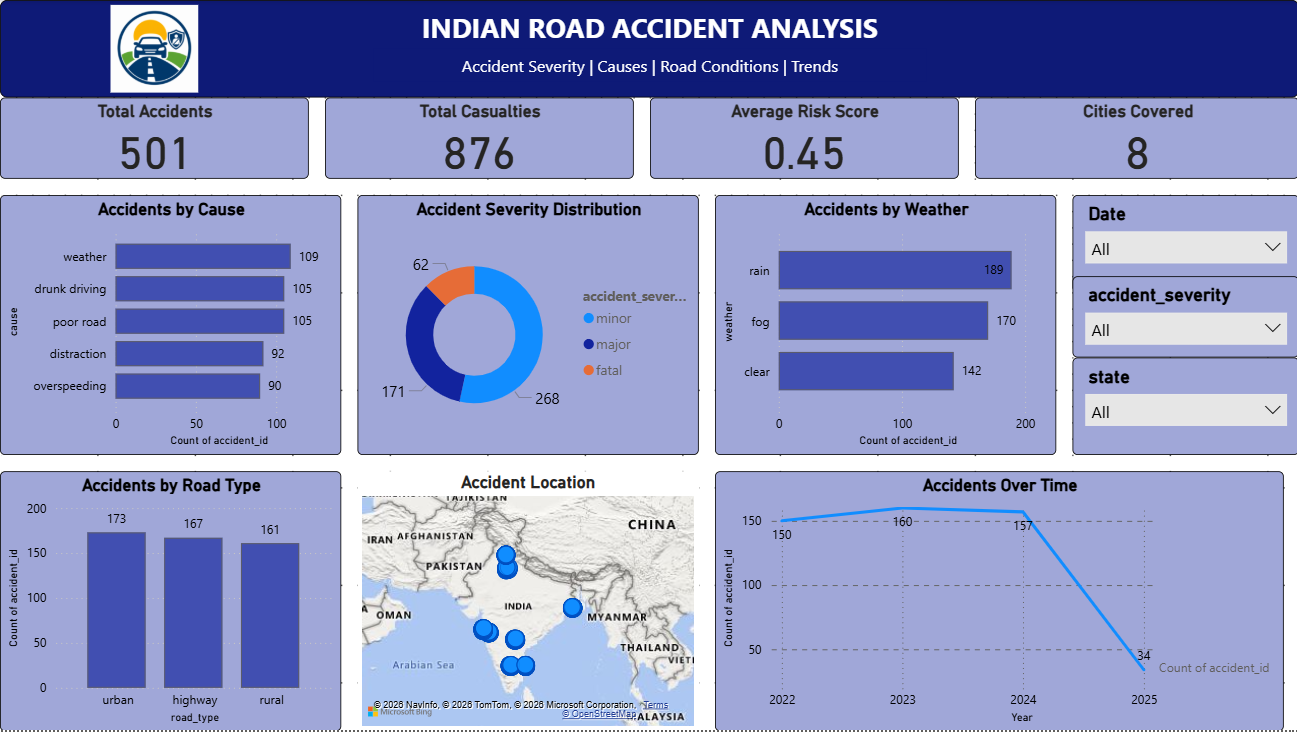

In [16]:
import os
from IPython.display import Image, display

# Define the target dashboard filename
target_file = 'Indian_Road_Accident_Dashboard.png'

# Fallback check: If the specific file doesn't exist, search for any recently uploaded PNG/JPG screenshot
if os.path.exists(target_file):
    display(Image(filename=target_file))
else:
    image_files = [f for f in os.listdir('.') if f.endswith(('.png', '.jpg', '.jpeg'))]
    if image_files:
        # Display the most recently uploaded image
        latest_image = max(image_files, key=os.path.getctime)
        print(f"'{target_file}' not found. Displaying the uploaded image: '{latest_image}'")
        display(Image(filename=latest_image))
    else:
        raise FileNotFoundError(
            f"Could not find '{target_file}' or any uploaded screenshot images. "
            "Please upload your dashboard screenshot using the cell above first."
        )

## Stage 4 – Documentation, Insights and Presentation

Show a dashboard aligning all the charts in powerbi by connecting python in PowerBI

Summarize findings in plain English (what do the patterns mean)

Highlight 3–5 key insights (trends, anomalies, correlations)

Provide recommendations for business or decision-making

Explain the FINAL STORY WITH THE DASHBOARD/report

Create a PDF pasting your DASHBOARD, explaining all the above mentioned concepts and submit it


**Step 1: Connect your Python-cleaned dataset to Power BI**
1. Open your Python project in Google Colab.
2. Run your data-cleaning code and download the cleaned CSV file, for example, Indian_Road_Accident_Cleaned.csv.
3. Open Power BI Desktop.
4. Click Home → Get data → Text/CSV.
5. Select your cleaned CSV file and click Open.
6. Check the preview and click Load.

**Step 2: Create and align all dashboard charts**


1. Add the dashboard title

Add a text box with the title INDIAN ROAD ACCIDENT ANALYSIS and subtitle Road Safety Insights | 2022–2025. Confirm the subtitle matches your dataset's actual date range.

2. Add four KPI cards
- Total Accidents — Count of accident_id
- Total Casualties — Sum of casualties
- Average Risk Score — Average of risk_score
- Cities Covered — Distinct count of city

3. Add charts for accident patterns
- Bar chart: Accidents by cause
- Donut chart: Accidents by accident_severity
- Column chart: Accidents by road_type
- Bar chart: Accidents by weather

4. Add a time trend and filters
- Line chart: date versus Count of accident_id
- Slicers: state, date, and accident_severity
- Optional map: latitude and longitude to explore accident locations.

**Step 3: Summarize the findings in plain English**

The Indian Road Accident Analysis project studies accident records to understand patterns based on accident causes, severity, road type, weather conditions, location, and time. Python was used to load, inspect, and clean the dataset, including handling missing values. Power BI was used to present the data through KPI cards, charts, and interactive filters. These visualizations help users understand how accident records differ across categories and time periods. The dashboard supports further investigation of road-safety patterns and helps identify areas that may need attention.

**Step 4: Highlight 3–5 key insights**

**Insight 1 — Accident causes**

Check which categories appear most frequently in the Accidents by Cause chart. State the most frequent cause only after checking the actual chart.


**Insight 2 — Accident severity**

Use the severity donut chart to compare the number of records in each severity category and identify the largest category.


**Insight 3 — Road type and weather**

Compare accident counts across road types and weather conditions. These differences may indicate patterns worth further investigation, but they do not prove that road type or weather caused the accidents.


**Insight 4 — Accident trends over time**

Examine the line chart to identify increases, decreases, or unusual peaks across the dates in your dataset.


**Insight 5 — Risk score and casualties**

Compare average risk scores and casualty counts across relevant categories. Investigate whether higher scores are associated with more casualties; do not assume a relationship without checking the data.

**Step 5: Provide recommendations for decision-making**

Based on the patterns identified in the dashboard, road-safety authorities can investigate locations and road types with high accident counts. Awareness programmes can promote safe driving, helmet use, seat-belt use, and avoiding mobile-phone distractions. Weather and visibility patterns can be reviewed to determine where additional safety measures may be useful. Accident trends by date and time can help authorities decide where further monitoring is needed. Regularly updating the dataset can improve future analysis and reporting. These recommendations should be reviewed against verified findings before taking action.

**Step 6: Explain the final story using the dashboard**

The final story of the Indian Road Accident Analysis project is to understand accident patterns using Python and Power BI. Python helps prepare the dataset by checking data types, identifying missing values, removing duplicate records where necessary, and performing exploratory data analysis. Power BI presents the cleaned data in an interactive dashboard containing accident KPIs, causes, severity, road types, weather conditions, and time trends. Users can apply filters to explore different states and accident categories. The dashboard helps highlight patterns that may require further investigation and supports data-driven road-safety planning. The analysis describes the records available in the dataset and does not establish the causes of accidents on its own.

**Step 7: Take a screenshot of your Power BI dashboard**

1. Open your completed dashboard in Power BI Desktop.


2. Adjust the report page so the title, cards, charts, and filters are visible together.


3. Press Windows + Shift + S on your keyboard.


4. Select the dashboard area and save the screenshot as a PNG image.

**Step 8: Create your final PDF report**


Add the project title: Indian Road Accident Analysis.



Add the following sections in order:
- Introduction and project objective
- Dataset description
- Python data cleaning and analysis
- Power BI dashboard screenshot
- Final dashboard observations and 3–5 key insights
- Recommendations for decision-making
- Final story and conclusion
- Future enhancements



To insert your dashboard, click Insert → Pictures → This Device and select the screenshot.



Paste the paragraphs from Steps 3, 5, and 6 into the corresponding sections.



Add the actual findings from your charts to Step 4.



Check that the screenshot and text fit neatly on the pages.



Click File → Save As and select PDF as the file type.



Save it as Indian_Road_Accident_Analysis_Report.pdf.

**Step 9: Final submission checklist**

Project completion


[1] Python-cleaned dataset prepared

[2] Cleaned dataset loaded into Power BI

[3] Dashboard charts and KPI cards aligned

[4] Dashboard screenshot inserted into report

[5] Three to five insights checked against actual charts

[6] Recommendations and final story included

[7] Report saved as PDF

[8] PDF opened and checked before submission


In [17]:
from google.colab import files
uploaded = files.upload()

Saving Screenshot 2026-10-26 192513.png to Screenshot 2026-10-26 192513 (1).png


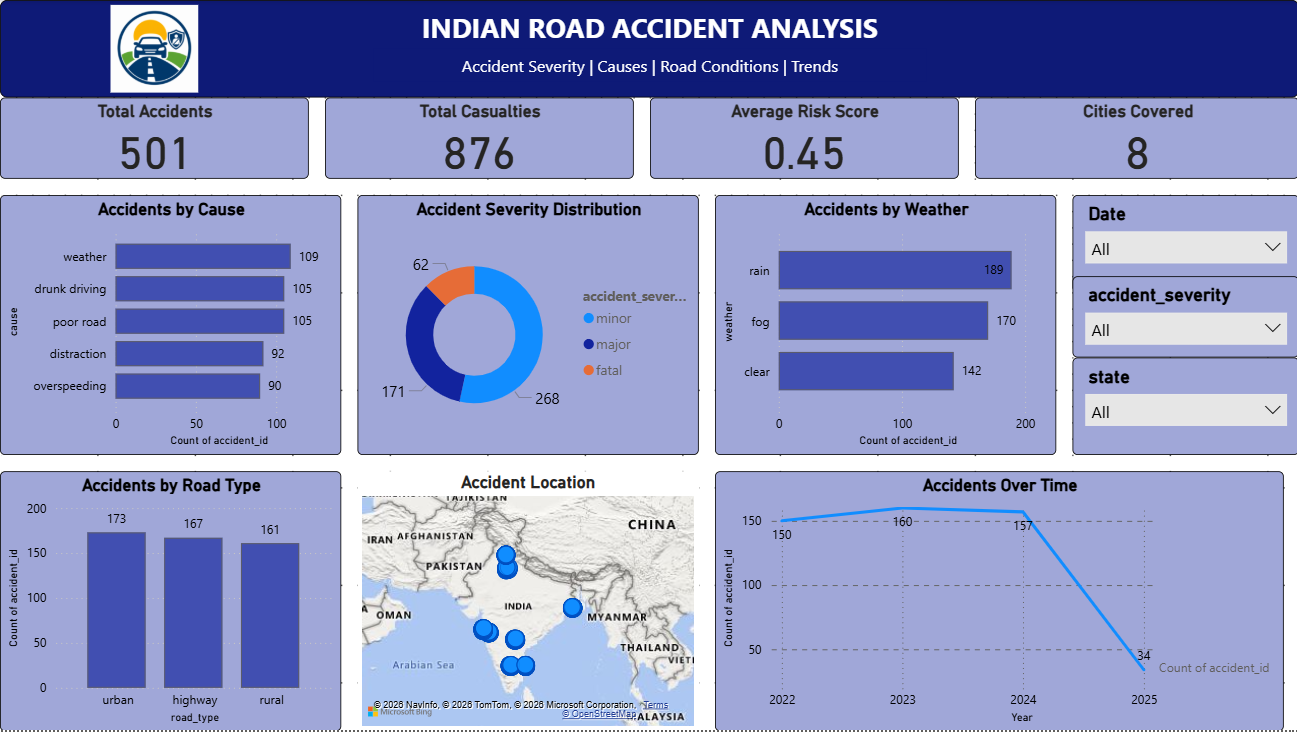

In [21]:
from IPython.display import Image, display

# Corrected filename with capitalized 'S' to match the uploaded file name
display(Image(filename='Screenshot 2026-10-26 192513.png'))

**Project explanation**

### **Power BI Dashboard** – **Indian Road Accident Analysis**

**Objective:** To analyze road accident patterns and identify important road safety trends in India.

**Dashboard Visualizations:**
- Total accidents and total casualties
- Accidents by cause and severity
- Accidents over time
- Accidents by road type and weather
- State, date, and severity filters

**Outcome:** The dashboard helps users explore accident patterns and understand road safety trends in the selected dataset.

## **Final Overall Insights:**

The Indian Road Accident Analysis project was carried out using Python and Power BI to understand road accident patterns in the selected dataset. The dataset contains information about accident locations, dates, times, causes, severity, road types, weather conditions, traffic density, casualties, and risk scores.

Python was used to inspect and clean the dataset, handle missing values, and perform Exploratory Data Analysis (EDA). Power BI was used to present the results through KPI cards, charts, and interactive filters.

The analysis helps explore how accident records vary by cause, severity, road type, weather, and time. It also allows users to examine casualties, vehicles involved, and risk scores to identify patterns that may require further investigation.

## Insights from the Final Dashboard Based on Four Types of Analysis

### **1. Univariate Analysis**

Univariate analysis examines one variable at a time.

In this project, variables such as `cause`, `accident_severity`, `road_type`, and `weather` can be analyzed individually using bar charts, donut charts, and frequency distributions.

**Dashboard Insight:** The charts help identify the most frequently recorded accident causes, severity categories, road types, and weather conditions. These results provide an overview of the characteristics of accidents in the dataset.

### **2. Bivariate Analysis**

Bivariate analysis examines the relationship between two variables.

In this project, accident records can be compared using combinations such as `weather` and `accident_severity`, `road_type` and `accident_id` counts, or `cause` and `casualties`.

**Dashboard Insight:** Comparing two variables helps reveal how accident counts or severity categories differ across road types, weather conditions, and recorded causes. These patterns can guide further investigation but do not establish that one factor caused an accident.

### **3. Multivariate Analysis**

Multivariate analysis examines three or more variables together.

In this project, `weather`, `road_type`, `traffic_density`, `accident_severity`, and `casualties` can be examined together using grouped summaries, pivot tables, and suitable visualizations.

**Dashboard Insight:** Examining multiple factors together provides a broader understanding of accident patterns. It helps identify combinations of conditions associated with higher recorded accident counts or more severe outcomes, where supported by the data.

### **4. Time-Series Analysis**

Time-series analysis examines how data changes over time.

In this project, the `date` and `hour` columns can be used to study accident records by date, month, year, or time of day. The `day_of_week`, `is_weekend`, `is_peak_hour`, and `festival` columns can provide additional context.

**Dashboard Insight:** The time-based charts help identify periods with relatively higher or lower recorded accident counts and explore differences between weekdays, weekends, and peak hours. These patterns can help determine where further analysis of traffic conditions may be useful.



# Future Enhancement

  Indian Road Accident Analysis
1. **Use a Larger and More Recent Dataset:** In the future, the project can include more Indian road accident records from different states and cities to identify road accident patterns more accurately.

2. **Automate the Analysis:** Python scripts can be used to automate data cleaning, missing-value handling, and data analysis. The Power BI dashboard can be refreshed when new accident data becomes available.

3. **Add Advanced Visualizations:** More interactive Power BI visualizations, such as maps, trend charts, and drill-down reports, can help users explore accidents by state, city, cause, severity, weather, and road type.

4. **Implement Predictive Modeling:** In the future, machine learning techniques can be explored to estimate accident risk or identify high-risk conditions using features such as time, weather, road type, and traffic density. The model would need sufficient quality data and proper testing.

# Conclusion

These future enhancements can make the Indian Road Accident Analysis project more informative and useful for understanding accident patterns and supporting road-safety planning.